# Ghost Guard App Model (Option B)

**Goal:** build, check and save the model the Ghost Guard app uses to score a dating chat.

**How the app uses it:** the user answers 16 onboarding questions once. For every pasted chat or screenshot, the app re-measures 3 of them from the user's **own** messages (messaging activity, emoji use, usual app time). The model then returns a LOW / MEDIUM / HIGH risk that the user gets ghosted:

> "Based on your dating profile and how you're messaging in this chat, your ghosting risk is HIGH."

**Link to the research:** same data (`ghosting.csv`), cleaning, features, train / validation / test split and model family as `Ghosting_Survey_ML_Pipeline_v2.ipynb`. Sections 04-09 use validation data only; the test set is used once, in section 12.

| Step | Section |
|---|---|
| 01 | Load + clean (same as v2) |
| 02 | Features + split (same as v2) |
| 03 | App input contract |
| 04 | Candidate models |
| 05 | Behaviour check: tips must never raise risk |
| 06 | Chat input influence |
| 07 | Robustness to chat measurement error |
| 08 | Select the app model (release gates) |
| 09 | Risk bands |
| 10 | Chat -> survey answer rules |
| 11 | End-to-end chat scoring + behaviour test chats |
| 12 | Final test evaluation (single use) |
| 13 | Save the model package |
| 14 | Summary |

# 01 Load + Clean (same as v2)

## CELL 1: Import Libraries

In [1]:
import re
import json
import platform
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, brier_score_loss

RANDOM_STATE = 42
OUT_DIR = Path('app_model')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__}")

Python 3.12.4 | scikit-learn 1.9.0


## CELL 2: Load and Clean the Survey

In [2]:
# Purpose: Identical cleaning to Ghosting_Survey_ML_Pipeline_v2.ipynb, so the app model comes from the same research data
df = pd.read_csv('ghosting.csv', encoding='utf-8')
df = df.drop(columns=['Respondent_ID', 'Submission_Timestamp'])
text_cols = df.select_dtypes(include='object').columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())
df = df.drop_duplicates().reset_index(drop=True)
df['Sexual_Orientation'] = df['Sexual_Orientation'].fillna('Not stated')
df['Income_Bracket_Self_Report'] = df['Income_Bracket_Self_Report'].fillna('Prefer not to say')
df['Interest_Tags'] = df['Interest_Tags'].fillna('').str.split(',').apply(
    lambda tags: ', '.join(t.strip().capitalize() for t in tags if t.strip()))
df['Reason_for_Ghosting'] = df['Reason_for_Ghosting'].fillna('Did not ghost')
df['Ghosted_Experience'] = df['Ghosted_Experience'].astype(int)
df['Ghosted_Others'] = df['Ghosted_Others'].astype(int)

TARGET = 'Ghosted_Experience'
assert len(df) == 13704, f"Expected 13,704 respondents after cleaning (as in v2), got {len(df)}"
print(f"Respondents: {len(df):,} | ghosted rate: {df[TARGET].mean():.3f}")

Respondents: 13,704 | ghosted rate: 0.520


# 02 Features + Split (same as v2)

## CELL 3: Answer Mappings and Feature Builder

In [3]:
ORDINAL_FEATURES = {
    'Daily_App_Use': ('App_Use_Minutes', {
        'Less than 15 minutes a day': 7.5, 'About 15–30 minutes a day': 22.5, 'About 30–60 minutes a day': 45,
        'About 1–2 hours a day': 90, 'More than 2 hours a day': 150}),
    'Swiping_Habit': ('Like_Ratio', {
        'I usually like only a small number of profiles': 0.1, 'I am fairly selective when choosing profiles': 0.3,
        'I like around half of the profiles I view': 0.5, 'I am fairly open when choosing profiles': 0.7,
        'I usually like most profiles I view': 0.9}),
    'Likes_Received_Estimate': ('Likes_Level', {
        'None or just a few': 0, 'A few': 1, 'Several': 2, 'Many': 3, 'A lot': 4}),
    'Matches_Experienced': ('Matches_Level', {
        'None so far': 0, 'A few matches': 1, 'Several matches': 2, 'Many matches': 3, 'A lot of matches': 4}),
    'Messaging_Activity': ('Messaging_Level', {
        'I usually have only a few messages with a match': 0, 'I usually have short conversations': 1,
        'I usually have moderately active conversations': 2, 'I am quite active in messaging matches': 3,
        'I am very active in messaging matches': 4}),
    'Emoji_Use_Frequency': ('Emoji_Level', {
        'Almost never': 0, 'Occasionally': 1, 'Sometimes': 2, 'Often': 3, 'Very often': 4}),
    'Bio_Detail_Level': ('Bio_Level', {
        'Very short (a line or less)': 0, 'Short (a few sentences)': 1, 'Medium (a short paragraph)': 2,
        'Detailed (several sentences/paragraphs)': 3, 'Very detailed': 4}),
    'Education_Level': ('Education_Score', {
        'High school': 0, 'Vocational / technical': 1, 'College / undergraduate': 2, 'Graduate': 3, 'Post-graduate': 4}),
    'Income_Bracket_Self_Report': ('Income_Level', {
        'Lower income range': 0, 'Middle income range': 1, 'Upper-middle income range': 2,
        'Higher income range': 3, 'Prefer not to say': 1}),
}
NIGHT = 'Late night / overnight (10 PM–5 AM)'
NOMINAL_COLS = ['Country', 'Gender', 'Sexual_Orientation', 'Location_Type', 'Usual_App_Use_Time', 'Swipe_Time_of_Day']

def clean_name(name):
    return re.sub(r'[^0-9A-Za-z]+', '_', str(name)).strip('_')

def map_ordinal(series, mapping):
    unmapped = set(series.unique()) - set(mapping)
    if unmapped:
        raise ValueError(f"{series.name}: no mapping for {unmapped}")
    return series.map(mapping)

def build_engineered_features(data):
    out = pd.DataFrame(index=data.index)
    out['Age'] = data['Age']
    out['Profile_Pics_Count'] = data['Profile_Pics_Count']
    for src, (new_col, mapping) in ORDINAL_FEATURES.items():
        out[new_col] = map_ordinal(data[src], mapping)
    out['Income_Not_Disclosed'] = (data['Income_Bracket_Self_Report'] == 'Prefer not to say').astype(int)

    # Match exposure: you cannot be ghosted without a match
    out['Has_Any_Match'] = (out['Matches_Level'] > 0).astype(int)
    out['Like_Match_Gap'] = out['Likes_Level'] - out['Matches_Level']
    out['Open_Swiper_x_Matches'] = out['Like_Ratio'] * out['Matches_Level']
    out['Likes_x_Matches'] = out['Likes_Level'] * out['Matches_Level']
    out['Emoji_x_Matches'] = out['Emoji_Level'] * out['Matches_Level']

    # Composite scores (0-1)
    out['Engagement_Index'] = (out['App_Use_Minutes'] / 150 + out['Messaging_Level'] / 4 + out['Emoji_Level'] / 4) / 3
    out['Profile_Effort'] = (out['Profile_Pics_Count'] / 8 + out['Bio_Level'] / 4) / 2

    # Time-of-day behaviour
    out['Night_App_User'] = (data['Usual_App_Use_Time'] == NIGHT).astype(int)
    out['Night_Swiper'] = (data['Swipe_Time_of_Day'] == NIGHT).astype(int)
    out['Time_Mismatch'] = (data['Usual_App_Use_Time'] != data['Swipe_Time_of_Day']).astype(int)

    # Interests and nominal categories
    tags = data['Interest_Tags'].str.get_dummies(sep=', ').add_prefix('Interest_')
    out['Interest_Count'] = tags.sum(axis=1)
    age_group = pd.cut(data['Age'], bins=[17, 24, 34, 44, 100], labels=['18_24', '25_34', '35_44', '45_plus'])
    nominal = pd.get_dummies(data[NOMINAL_COLS].assign(Age_Group=age_group),
                             columns=NOMINAL_COLS + ['Age_Group'], dtype=int)
    out = pd.concat([out, tags, nominal], axis=1)
    out.columns = [clean_name(c) for c in out.columns]
    return out.astype(float)

def features_for(rows):
    # Survey answers -> model features, always with exactly the columns the model was trained on
    return build_engineered_features(rows).reindex(columns=X_eng.columns, fill_value=0.0)

## CELL 4: Train / Validation / Test Split

In [4]:
X_eng = build_engineered_features(df)
y = df[TARGET]
assert X_eng.isnull().sum().sum() == 0 and X_eng.columns.is_unique

strata = y.astype(str) + '_' + X_eng['Has_Any_Match'].astype(int).astype(str)
idx_temp, idx_test = train_test_split(df.index, test_size=0.20, stratify=strata, random_state=RANDOM_STATE)
idx_train, idx_val = train_test_split(idx_temp, test_size=0.25, stratify=strata.loc[idx_temp], random_state=RANDOM_STATE)
y_train, y_val, y_test = y.loc[idx_train], y.loc[idx_val], y.loc[idx_test]
rows_train, rows_val, rows_test = df.loc[idx_train], df.loc[idx_val], df.loc[idx_test]

NOISY_PREFIXES = ('Interest_', 'Country_')
LEAN_COLS = [c for c in X_eng.columns if not c.startswith(NOISY_PREFIXES)]
SPLINE_COLS = [c for c in LEAN_COLS if X_eng[c].nunique() > 2]
BINARY_COLS = [c for c in LEAN_COLS if c not in SPLINE_COLS]

assert (len(idx_train), len(idx_val), len(idx_test)) == (8222, 2741, 2741), "Split differs from v2"
assert np.allclose(features_for(rows_val).values, X_eng.loc[idx_val].values)
print(f"Features: {X_eng.shape[1]} (lean: {len(LEAN_COLS)}) | "
      f"train {len(idx_train):,} | validation {len(idx_val):,} | test {len(idx_test):,}")

Features: 89 (lean: 50) | train 8,222 | validation 2,741 | test 2,741


## CELL 5: Reproduce the v2 Deployment Model

In [5]:
def make_spline_lr():
    return Pipeline([('features', ColumnTransformer([('splines', SplineTransformer(n_knots=4, degree=3), SPLINE_COLS),
                                                     ('binary', 'passthrough', BINARY_COLS)])),
                     ('scaler', StandardScaler()),
                     ('clf', LogisticRegression(C=0.1, max_iter=5000))])

def make_lean_lr():
    return Pipeline([('select', ColumnTransformer([('keep', 'passthrough', LEAN_COLS)])),
                     ('scaler', StandardScaler()),
                     ('clf', LogisticRegression(C=0.1, max_iter=5000))])

# Purpose: The app model must be the same model the research evaluated
reproduced = make_spline_lr().fit(X_eng.loc[idx_train], y_train)
reproduced_val = reproduced.predict_proba(X_eng.loc[idx_val])[:, 1]
print(f"Spline LR (lean) validation ROC-AUC: {roc_auc_score(y_val, reproduced_val):.4f} (v2: 0.9002)")
assert abs(roc_auc_score(y_val, reproduced_val) - 0.9002) < 0.0005

v2_file = Path('ghosting_spline_lr_deploy.pkl')
if v2_file.exists():
    assert np.allclose(joblib.load(v2_file)['model'].predict_proba(X_eng.loc[idx_val])[:, 1], reproduced_val)
    print("Identical predictions to the model saved by v2 (ghosting_spline_lr_deploy.pkl)")
else:
    print("v2 model file not found - reproduction checked against the v2 validation score only")

Spline LR (lean) validation ROC-AUC: 0.9002 (v2: 0.9002)
Identical predictions to the model saved by v2 (ghosting_spline_lr_deploy.pkl)


# 03 App Input Contract

Onboarding asks 16 questions. Three of them (messaging activity, emoji use, usual app time) are **re-measured from every chat**; the onboarding answer is kept as the fallback when a chat is too short to judge. Country and interests are not used by the lean model, so the app does not need them.

## CELL 6: Questions and Allowed Answers

In [6]:
TIME_BANDS = ['Early morning (5–9 AM)', 'Late morning (9 AM–12 PM)', 'Afternoon (12–5 PM)',
              'Evening (5–10 PM)', 'Late night / overnight (10 PM–5 AM)']
LEVELS = {q: [a for a, _ in sorted(mapping.items(), key=lambda kv: kv[1])] for q, (_, mapping) in ORDINAL_FEATURES.items()}
LEVELS['Income_Bracket_Self_Report'] = ['Lower income range', 'Middle income range', 'Upper-middle income range',
                                        'Higher income range', 'Prefer not to say']
LEVELS['Usual_App_Use_Time'] = TIME_BANDS
LEVELS['Swipe_Time_of_Day'] = TIME_BANDS
LEVELS['Profile_Pics_Count'] = list(range(1, 9))
for q in ['Gender', 'Sexual_Orientation', 'Location_Type']:
    LEVELS[q] = sorted(df[q].unique())

PROFILE_QUESTIONS = ['Age', 'Gender', 'Sexual_Orientation', 'Location_Type', 'Education_Level',
                     'Income_Bracket_Self_Report', 'Daily_App_Use', 'Swiping_Habit', 'Likes_Received_Estimate',
                     'Matches_Experienced', 'Swipe_Time_of_Day', 'Profile_Pics_Count', 'Bio_Detail_Level']
CHAT_QUESTIONS = ['Messaging_Activity', 'Emoji_Use_Frequency', 'Usual_App_Use_Time']
ONBOARDING_QUESTIONS = PROFILE_QUESTIONS + CHAT_QUESTIONS
NOT_USED = ['Country', 'Interest_Tags']
AGE_RANGE = (18, 65)   # the model was trained on ages 18-65; older ages are scored as 65

for q in ONBOARDING_QUESTIONS:
    if q != 'Age':
        assert set(df[q].unique()) <= set(LEVELS[q]), f"{q}: a survey answer is missing from the allowed list"

contract = pd.DataFrame({
    'question': ONBOARDING_QUESTIONS,
    'measured from each chat': [q in CHAT_QUESTIONS for q in ONBOARDING_QUESTIONS],
    'allowed answers': [f"whole number, {AGE_RANGE[0]}+" if q == 'Age' else len(LEVELS[q]) for q in ONBOARDING_QUESTIONS],
})
print(f"Onboarding questions: {len(ONBOARDING_QUESTIONS)} | re-measured from each chat: {len(CHAT_QUESTIONS)}")
contract

Onboarding questions: 16 | re-measured from each chat: 3


,question,measured from each chat,allowed answers
0,Age,False,"whole number, 18+"
1,Gender,False,3
2,Sexual_Orientation,False,8
3,Location_Type,False,3
4,Education_Level,False,5
5,Income_Bracket_Self_Report,False,5
6,Daily_App_Use,False,5
7,Swiping_Habit,False,5
8,Likes_Received_Estimate,False,5
9,Matches_Experienced,False,5


## CELL 7: Confirm Country and Interests Are Not Used

In [7]:
probe = rows_val.assign(Country=rows_val['Country'].iloc[0], Interest_Tags='')
unchanged = np.allclose(reproduced.predict_proba(features_for(rows_val))[:, 1],
                        reproduced.predict_proba(features_for(probe))[:, 1])
print("Predictions unchanged when country and interests are replaced:", unchanged)
assert unchanged

Predictions unchanged when country and interests are replaced: True


# 04 Candidate Models

**Spline LR (lean)** is the deployment model chosen in v2. **Logistic Regression (lean)** is the fallback: a plain linear model is guaranteed to move risk in one direction per answer, which matters if the spline bends.

## CELL 8: Cross-Validated and Validation Scores

In [8]:
CANDIDATES = {'Spline LR (lean)': make_spline_lr, 'Logistic Regression (lean)': make_lean_lr}

def oof_auc(make_model):
    X_tr, oof = X_eng.loc[idx_train], np.zeros(len(y_train))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X_tr, y_train):
        oof[te] = make_model().fit(X_tr.iloc[tr], y_train.iloc[tr]).predict_proba(X_tr.iloc[te])[:, 1]
    return roc_auc_score(y_train, oof)

fitted, val_scores, records = {}, {}, []
for name, make in CANDIDATES.items():
    fitted[name] = make().fit(X_eng.loc[idx_train], y_train)
    val_scores[name] = fitted[name].predict_proba(X_eng.loc[idx_val])[:, 1]
    records.append({'Model': name, 'CV ROC-AUC (train)': oof_auc(make),
                    'Validation ROC-AUC': roc_auc_score(y_val, val_scores[name]),
                    'Validation Brier': brier_score_loss(y_val, val_scores[name])})
pd.DataFrame(records).round(4)

,Model,CV ROC-AUC (train),Validation ROC-AUC,Validation Brier
0,Spline LR (lean),0.8944,0.9002,0.1282
1,Logistic Regression (lean),0.8928,0.8983,0.1292


# 05 Behaviour Check: Tips Must Never Raise Risk

Every validation user is re-scored at each level of one question while all other answers stay the same. A question can only be used for tips if its effect points in **the same direction for every user**. The release gate requires that more active messaging never raises anyone's risk.

## CELL 9: Risk Across Answer Levels

In [9]:
TIP_QUESTIONS = ['Messaging_Activity', 'Emoji_Use_Frequency', 'Bio_Detail_Level', 'Profile_Pics_Count',
                 'Daily_App_Use', 'Swiping_Habit']

def risk_by_level(model, rows, question):
    return np.column_stack([model.predict_proba(features_for(rows.assign(**{question: level})))[:, 1]
                            for level in LEVELS[question]])

def behaviour_check(model, rows):
    out = []
    for q in TIP_QUESTIONS:
        P = risk_by_level(model, rows, q)
        steps = np.diff(P, axis=1)
        never_up = np.all(steps <= 1e-9, axis=1).mean()
        never_down = np.all(steps >= -1e-9, axis=1).mean()
        change = (P[:, -1] - P[:, 0]).mean()
        out.append({'question': q,
                    'users: higher level never raises risk': never_up,
                    'users: higher level never lowers risk': never_down,
                    'mean risk change (lowest -> highest level)': change,
                    'same direction for every user': max(never_up, never_down) == 1.0,
                    'direction': 'higher level lowers risk' if change < 0 else 'higher level raises risk'})
    return pd.DataFrame(out)

behaviour = {name: behaviour_check(model, rows_val) for name, model in fitted.items()}
for name, table in behaviour.items():
    print(f"\n=== {name} ===")
    print(table.round(4).to_string(index=False))


=== Spline LR (lean) ===
           question  users: higher level never raises risk  users: higher level never lowers risk  mean risk change (lowest -> highest level)  same direction for every user                direction
 Messaging_Activity                                 1.0000                                 0.0000                                     -0.3469                           True higher level lowers risk
Emoji_Use_Frequency                                 0.3050                                 0.0000                                     -0.0601                          False higher level lowers risk
   Bio_Detail_Level                                 1.0000                                 0.0000                                     -0.2635                           True higher level lowers risk
 Profile_Pics_Count                                 0.6162                                 0.0000                                     -0.1962                          False higher le

## CELL 10: Mean Risk by Messaging Activity

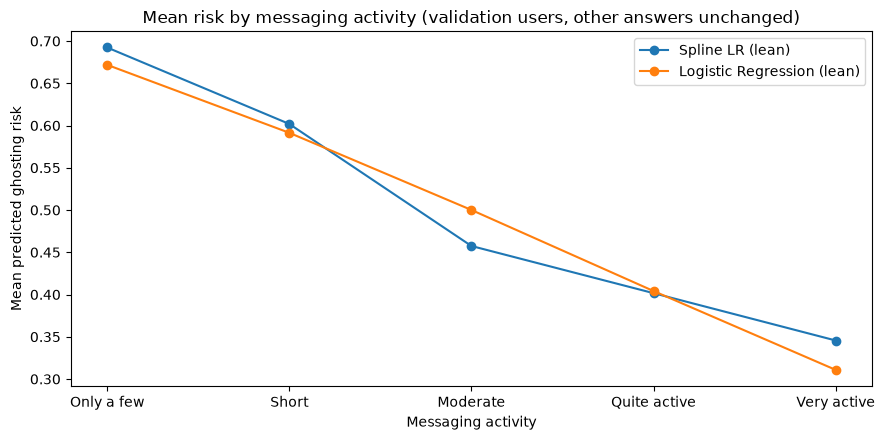

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, model in fitted.items():
    ax.plot(['Only a few', 'Short', 'Moderate', 'Quite active', 'Very active'],
            risk_by_level(model, rows_val, 'Messaging_Activity').mean(axis=0), marker='o', label=name)
ax.set_xlabel('Messaging activity')
ax.set_ylabel('Mean predicted ghosting risk')
ax.set_title('Mean risk by messaging activity (validation users, other answers unchanged)')
ax.legend()
plt.tight_layout()
plt.show()

# 06 Chat Input Influence

How far can each answer move one user's risk? The spread is the largest minus the smallest risk across that question's levels, with everything else unchanged. Profile questions are shown for comparison.

## CELL 11: Risk Range per Question

In [11]:
records = []
for q in CHAT_QUESTIONS + ['Matches_Experienced', 'Swiping_Habit', 'Bio_Detail_Level']:
    for name, model in fitted.items():
        P = risk_by_level(model, rows_val, q)
        records.append({'source': 'chat' if q in CHAT_QUESTIONS else 'profile', 'question': q, 'model': name,
                        'mean risk range': (P.max(axis=1) - P.min(axis=1)).mean()})
influence = pd.DataFrame(records).pivot_table(index=['source', 'question'], columns='model', values='mean risk range')
influence.round(3)

model                        Logistic Regression (lean)  Spline LR (lean)
source  question                                                         
chat    Emoji_Use_Frequency                       0.032             0.063
        Messaging_Activity                        0.361             0.347
        Usual_App_Use_Time                        0.117             0.128
profile Bio_Detail_Level                          0.250             0.264
        Matches_Experienced                       0.921             0.887
        Swiping_Habit                             0.421             0.335

# 07 Robustness to Chat Measurement Error

One chat is not the same as a long-term habit. The onboarding answers act as the "true" habits, and a share of users get chat answers that are up to one level off (messaging, emoji) or one time band off. The last scenario replaces all three chat answers with random answers drawn from the survey's answer mix.

## CELL 12: Simulated Measurement Error

In [12]:
SHARES = [0.0, 0.25, 0.5, 0.75, 1.0]
REPEATS = 20

def shift_answers(rows, share, rng):
    noisy = rows.copy()
    for q in CHAT_QUESTIONS:
        levels = LEVELS[q]
        pos = noisy[q].map({a: i for i, a in enumerate(levels)}).to_numpy()
        hit = rng.random(len(noisy)) < share
        new_pos = np.clip(pos + np.where(hit, rng.choice([-1, 1], size=len(noisy)), 0), 0, len(levels) - 1)
        noisy[q] = [levels[i] for i in new_pos]
    return noisy

def random_chat_answers(rows, rng):
    noisy = rows.copy()
    for q in CHAT_QUESTIONS:
        mix = df[q].value_counts(normalize=True)
        noisy[q] = rng.choice(mix.index.to_numpy(), size=len(noisy), p=mix.to_numpy())
    return noisy

rng = np.random.default_rng(RANDOM_STATE)
records = []
for name, model in fitted.items():
    for share in SHARES:
        aucs = [roc_auc_score(y_val, model.predict_proba(features_for(shift_answers(rows_val, share, rng)))[:, 1])
                for _ in range(REPEATS if share > 0 else 1)]
        records.append({'model': name, 'scenario': f'{share:.0%} of users up to one level off', 'share': share,
                        'ROC-AUC mean': np.mean(aucs), 'ROC-AUC sd': np.std(aucs)})
    aucs = [roc_auc_score(y_val, model.predict_proba(features_for(random_chat_answers(rows_val, rng)))[:, 1])
            for _ in range(REPEATS)]
    records.append({'model': name, 'scenario': 'chat answers completely random', 'share': np.nan,
                    'ROC-AUC mean': np.mean(aucs), 'ROC-AUC sd': np.std(aucs)})
robustness = pd.DataFrame(records)
robustness.drop(columns='share').round(4)

,model,scenario,ROC-AUC mean,ROC-AUC sd
0,Spline LR (lean),0% of users up to one level off,0.9002,0.0000
1,Spline LR (lean),25% of users up to one level off,0.8952,0.0019
2,Spline LR (lean),50% of users up to one level off,0.8900,0.0022
3,Spline LR (lean),75% of users up to one level off,0.8845,0.0023
4,Spline LR (lean),100% of users up to one level off,0.8800,0.0032
5,Spline LR (lean),chat answers completely random,0.8376,0.0036
6,Logistic Regression (lean),0% of users up to one level off,0.8983,0.0000
7,Logistic Regression (lean),25% of users up to one level off,0.8935,0.0015
8,Logistic Regression (lean),50% of users up to one level off,0.8895,0.0019
9,Logistic Regression (lean),75% of users up to one level off,0.8851,0.0027


## CELL 13: Robustness Curve

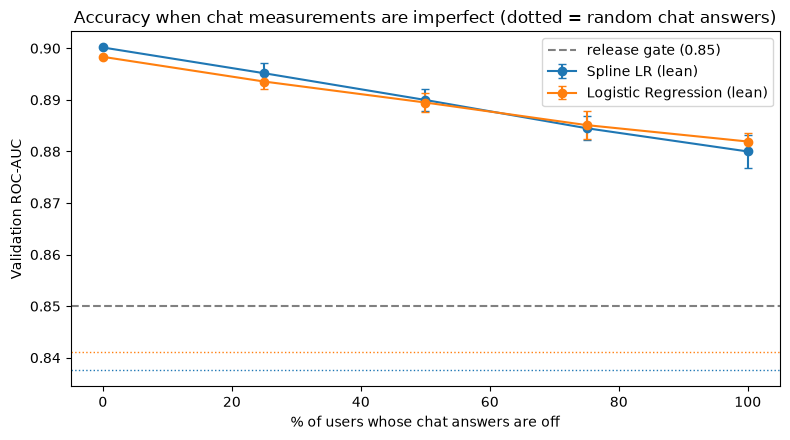

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name in fitted:
    part = robustness[(robustness['model'] == name) & robustness['share'].notna()]
    ax.errorbar(part['share'] * 100, part['ROC-AUC mean'], yerr=part['ROC-AUC sd'], marker='o', capsize=3, label=name)
    worst = robustness[(robustness['model'] == name) & robustness['share'].isna()]['ROC-AUC mean'].iloc[0]
    ax.axhline(worst, ls=':', lw=1, color=ax.lines[-1].get_color())
ax.axhline(0.85, ls='--', c='grey', label='release gate (0.85)')
ax.set_xlabel('% of users whose chat answers are off')
ax.set_ylabel('Validation ROC-AUC')
ax.set_title('Accuracy when chat measurements are imperfect (dotted = random chat answers)')
ax.legend()
plt.tight_layout()
plt.show()

# 08 Select the App Model

**Release gates** (validation data):

1. Validation ROC-AUC >= 0.89
2. ROC-AUC >= 0.85 when 50% of users' chat answers are off
3. More active messaging never raises risk, for 100% of users

**Pre-declared rule:** use Spline LR (the v2 deployment choice) if it passes every gate, otherwise the plain lean model. If neither passes, the model is not released.

## CELL 14: Release Gates

In [14]:
records = []
for name in fitted:
    msg = behaviour[name].set_index('question').loc['Messaging_Activity']
    robust50 = robustness[(robustness['model'] == name) & (robustness['share'] == 0.5)]['ROC-AUC mean'].iloc[0]
    val_auc = roc_auc_score(y_val, val_scores[name])
    checks = {
        'Gate 1: validation ROC-AUC >= 0.89': val_auc >= 0.89,
        'Gate 2: ROC-AUC (50% off) >= 0.85': robust50 >= 0.85,
        'Gate 3: messaging never raises risk': msg['users: higher level never raises risk'] == 1.0,
    }
    records.append({'Model': name, 'Validation ROC-AUC': round(val_auc, 4), 'ROC-AUC (50% off)': round(robust50, 4),
                    **checks, 'Passes all gates': all(checks.values())})
gate_table = pd.DataFrame(records)

passing = gate_table.set_index('Model')['Passes all gates']
APP_MODEL_NAME = next((m for m in ['Spline LR (lean)', 'Logistic Regression (lean)'] if passing[m]), None)
assert APP_MODEL_NAME is not None, "No candidate passed every gate - the app model must not be released."
app_model = fitted[APP_MODEL_NAME]
MODEL_VERSION = 'ghost_guard_' + ('splinelr' if APP_MODEL_NAME.startswith('Spline') else 'lr') + '_v1'
print(f"Selected app model: {APP_MODEL_NAME} ({MODEL_VERSION})")
gate_table

Selected app model: Spline LR (lean) (ghost_guard_splinelr_v1)


,Model,Validation ROC-AUC,ROC-AUC (50% off),Gate 1: validation ROC-AUC >= 0.89,Gate 2: ROC-AUC (50% off) >= 0.85,Gate 3: messaging never raises risk,Passes all gates
0,Spline LR (lean),0.9002,0.8900,True,True,True,True
1,Logistic Regression (lean),0.8983,0.8895,True,True,True,True


# 09 Risk Bands

The app already shows LOW / MEDIUM / HIGH at cut-offs 0.33 and 0.66, so the same cut-offs are used. Each band must contain a clearly different real ghosted rate.

## CELL 15: Real Ghosted Rate per Band (Validation)

In [15]:
BAND_EDGES = (0.33, 0.66)

def to_band(p):
    return np.where(p < BAND_EDGES[0], 'LOW', np.where(p < BAND_EDGES[1], 'MEDIUM', 'HIGH'))

def band_table(y_true, proba):
    t = pd.DataFrame({'band': to_band(proba), 'ghosted': np.asarray(y_true), 'predicted': proba})
    out = t.groupby('band').agg(users=('ghosted', 'size'), real_ghosted_rate=('ghosted', 'mean'),
                                mean_predicted_risk=('predicted', 'mean')).reindex(['LOW', 'MEDIUM', 'HIGH'])
    out['share_of_users'] = out['users'] / out['users'].sum()
    return out

val_bands = band_table(y_val, val_scores[APP_MODEL_NAME])
rates = val_bands['real_ghosted_rate'].to_numpy()
assert rates[0] < rates[1] < rates[2], "Bands are not correctly ordered"
assert rates[2] - rates[0] >= 0.30, "HIGH and LOW bands are not clearly different"
no_match = (rows_val['Matches_Experienced'] == 'None so far').to_numpy()
print(f"Validation users with no matches: {no_match.sum()} | all scored LOW: "
      f"{bool((to_band(val_scores[APP_MODEL_NAME][no_match]) == 'LOW').all())}")
val_bands.round(3)

Validation users with no matches: 388 | all scored LOW: True


,users,real_ghosted_rate,mean_predicted_risk,share_of_users
band,,,,
LOW,950,0.097,0.100,0.347
MEDIUM,585,0.528,0.501,0.213
HIGH,1206,0.850,0.865,0.440


# 10 Chat -> Survey Answer Rules

These rules turn what the app can measure in the user's own messages into survey answers. They are **starting rules**: once about 500 real chats are logged, the cut-offs should be re-set so the share of chats in each answer matches the survey (quantile matching), and then checked against real outcomes from the 14-day follow-up.

- **Messaging activity:** a 0-1 score from message length and how often the user asks questions. The score cut-offs equal the survey's cumulative answer shares, so an evenly spread score reproduces the survey's answer mix. Message *count* is deliberately not used: in a pasted excerpt it measures how much was pasted, not how active the user is.
- **Emoji use:** emojis per message.
- **Usual app time:** the most common time band of the user's message timestamps.

## CELL 16: Measurement Rules (Provisional)

In [16]:
MESSAGING_SHARES = df['Messaging_Activity'].value_counts(normalize=True).reindex(LEVELS['Messaging_Activity'])
EMOJI_SHARES = df['Emoji_Use_Frequency'].value_counts(normalize=True).reindex(LEVELS['Emoji_Use_Frequency'])

CHAT_RULES = {
    'status': 'provisional - recalibrate by quantile matching after about 500 logged chats',
    'min_own_messages': 5,    # fewer of the user's own messages -> onboarding answers for messaging and emoji
    'min_timestamps': 3,      # fewer timestamps on the user's messages -> onboarding answer for app time
    'messaging_activity': {
        'score': '0.6 * min(average characters per own message / 100, 1) + 0.4 * share of own messages containing ?',
        'cutoffs': MESSAGING_SHARES.cumsum().iloc[:-1].round(4).tolist(),
        'levels': LEVELS['Messaging_Activity'],
        'survey_shares': MESSAGING_SHARES.round(4).tolist(),
    },
    'emoji_use': {
        'score': 'emojis per own message',
        'cutoffs': [1e-9, 0.15, 0.5, 1.0],
        'levels': LEVELS['Emoji_Use_Frequency'],
        'survey_shares': EMOJI_SHARES.round(4).tolist(),
    },
    'app_time': {
        'rule': 'most common time band of own message timestamps (tie -> band of the latest message)',
        'band_hours': {TIME_BANDS[0]: [5, 6, 7, 8], TIME_BANDS[1]: [9, 10, 11], TIME_BANDS[2]: [12, 13, 14, 15, 16],
                       TIME_BANDS[3]: [17, 18, 19, 20, 21], TIME_BANDS[4]: [22, 23, 0, 1, 2, 3, 4]},
    },
}
assert sorted(h for hours in CHAT_RULES['app_time']['band_hours'].values() for h in hours) == list(range(24))
print(json.dumps(CHAT_RULES, indent=1, ensure_ascii=False))

{
 "status": "provisional - recalibrate by quantile matching after about 500 logged chats",
 "min_own_messages": 5,
 "min_timestamps": 3,
 "messaging_activity": {
  "score": "0.6 * min(average characters per own message / 100, 1) + 0.4 * share of own messages containing ?",
  "cutoffs": [
   0.1844,
   0.4244,
   0.6952,
   0.9
  ],
  "levels": [
   "I usually have only a few messages with a match",
   "I usually have short conversations",
   "I usually have moderately active conversations",
   "I am quite active in messaging matches",
   "I am very active in messaging matches"
  ],
  "survey_shares": [
   0.1844,
   0.24,
   0.2708,
   0.2048,
   0.1
  ]
 },
 "emoji_use": {
  "score": "emojis per own message",
  "cutoffs": [
   1e-09,
   0.15,
   0.5,
   1.0
  ],
  "levels": [
   "Almost never",
   "Occasionally",
   "Sometimes",
   "Often",
   "Very often"
  ],
  "survey_shares": [
   0.142,
   0.2955,
   0.3942,
   0.1424,
   0.0259
  ]
 },
 "app_time": {
  "rule": "most common time

# 11 End-to-End Chat Scoring

A reference implementation of what the backend will do for a pasted chat. A screenshot follows the same path once OCR has turned it into `Name: message` lines.

1. Parse the chat into messages (speaker, text, hour if a timestamp is present)
2. Measure the user's **own** messages
3. Convert the measurements into the three chat answers (onboarding answers as fallback)
4. Score onboarding answers + chat answers with the app model
5. Add up to two tips, using only questions that passed the behaviour check

## CELL 17: Chat Parser and Behaviour Measurement

In [17]:
LINE = re.compile(
    r'^\s*\[?(?:\d{1,2}[/.-]\d{1,2}[/.-]\d{2,4},?\s*)?(?:(?P<hh>\d{1,2}):(?P<mm>\d{2})\s*(?P<ampm>[AaPp]\.?[Mm]\.?)?)?\]?'
    r'\s*(?:-|–)?\s*(?P<speaker>[^:\n]{1,30}?)\s*:\s*(?P<msg>.*\S.*)$')
EMOJI = re.compile('[\U0001F1E6-\U0001F1FF\U0001F300-\U0001FAFF☀-➿]')

def parse_chat(text):
    messages = []
    for raw in text.splitlines():
        if not raw.strip():
            continue
        m = LINE.match(raw)
        if m:
            hour = None
            if m.group('hh') is not None:
                hour = int(m.group('hh')) % 24
                ampm = (m.group('ampm') or '').lower().replace('.', '')
                if ampm == 'pm' and hour < 12:
                    hour += 12
                elif ampm == 'am' and hour == 12:
                    hour = 0
            messages.append({'speaker': m.group('speaker').strip(), 'text': m.group('msg').strip(), 'hour': hour})
        elif messages:
            messages[-1]['text'] += ' ' + raw.strip()   # continuation line of the previous message
    if len({msg['speaker'].lower() for msg in messages}) < 2:
        raise ValueError("Could not find two speakers. Use one 'Name: message' line per message.")
    return messages

def measure_own_behaviour(messages, user_label):
    own = [m for m in messages if m['speaker'].lower() == user_label.strip().lower()]
    if not own:
        raise ValueError(f"No messages from '{user_label}' were found in the chat.")
    return {
        'own_messages': len(own),
        'avg_chars': float(np.mean([len(m['text']) for m in own])),
        'question_share': sum('?' in m['text'] for m in own) / len(own),
        'emoji_per_message': sum(len(EMOJI.findall(m['text'])) for m in own) / len(own),
        'hours': [m['hour'] for m in own if m['hour'] is not None],
    }

def level_from_score(score, rule):
    return rule['levels'][int(np.searchsorted(rule['cutoffs'], score, side='right'))]

def hour_band(hour):
    return next(band for band, hours in CHAT_RULES['app_time']['band_hours'].items() if hour in hours)

def chat_answers(measure, profile):
    answers, from_profile = {}, []
    if measure['own_messages'] >= CHAT_RULES['min_own_messages']:
        activity = 0.6 * min(measure['avg_chars'] / 100, 1) + 0.4 * measure['question_share']
        answers['Messaging_Activity'] = level_from_score(activity, CHAT_RULES['messaging_activity'])
        answers['Emoji_Use_Frequency'] = level_from_score(measure['emoji_per_message'], CHAT_RULES['emoji_use'])
    else:
        answers['Messaging_Activity'] = profile['Messaging_Activity']
        answers['Emoji_Use_Frequency'] = profile['Emoji_Use_Frequency']
        from_profile += ['Messaging_Activity', 'Emoji_Use_Frequency']
    if len(measure['hours']) >= CHAT_RULES['min_timestamps']:
        bands = [hour_band(h) for h in measure['hours']]
        counts = pd.Series(bands).value_counts()
        top = list(counts[counts == counts.max()].index)
        answers['Usual_App_Use_Time'] = bands[-1] if bands[-1] in top else top[0]
    else:
        answers['Usual_App_Use_Time'] = profile['Usual_App_Use_Time']
        from_profile.append('Usual_App_Use_Time')
    return answers, from_profile

formats = parse_chat("You: hi\n[22:15] Alex: hey there\n12/09/2026, 9:05 PM - You: how are you?")
assert [m['speaker'] for m in formats] == ['You', 'Alex', 'You'] and [m['hour'] for m in formats] == [None, 22, 21]
print("Parser handles 'Name: msg', '[HH:MM] Name: msg' and 'date, H:MM PM - Name: msg'")

Parser handles 'Name: msg', '[HH:MM] Name: msg' and 'date, H:MM PM - Name: msg'


## CELL 18: Score a Chat

In [18]:
app_behaviour = behaviour[APP_MODEL_NAME].set_index('question')
# +1: moving to a higher level lowers risk, -1: moving to a lower level lowers risk
TIP_RULES = {q: (1 if r['direction'] == 'higher level lowers risk' else -1)
             for q, r in app_behaviour.iterrows()
             if r['same direction for every user'] and abs(r['mean risk change (lowest -> highest level)']) >= 0.01}
print("Questions eligible for tips:", {q: ('higher level lowers risk' if d == 1 else 'lower level lowers risk')
                                       for q, d in TIP_RULES.items()})

def validate_profile(profile):
    missing = [q for q in ONBOARDING_QUESTIONS if q not in profile]
    if missing:
        raise ValueError(f"Profile is missing: {missing}")
    clean = dict(profile)
    if int(clean['Age']) < AGE_RANGE[0]:
        raise ValueError("Ghost Guard is for users aged 18 or over.")
    clean['Age'] = min(int(clean['Age']), AGE_RANGE[1])
    clean['Profile_Pics_Count'] = int(np.clip(int(clean['Profile_Pics_Count']), 1, 8))
    for q in ONBOARDING_QUESTIONS:
        if q not in ('Age', 'Profile_Pics_Count') and clean[q] not in LEVELS[q]:
            raise ValueError(f"{q}: '{clean[q]}' is not an allowed answer")
    return clean

def risk_for(answers, model):
    row = pd.DataFrame([{**answers, 'Country': 'not_used', 'Interest_Tags': ''}])
    return float(model.predict_proba(features_for(row))[:, 1][0])

def score_chat(profile, chat_text, user_label='You', model=None):
    model = model or app_model
    profile = validate_profile(profile)
    measure = measure_own_behaviour(parse_chat(chat_text), user_label)
    chat_based, from_profile = chat_answers(measure, profile)
    answers = {**profile, **chat_based}
    risk, baseline = risk_for(answers, model), risk_for(profile, model)

    tips = []
    for q, better in TIP_RULES.items():
        levels = LEVELS[q]
        target = levels.index(answers[q]) + better
        if 0 <= target < len(levels):
            drop = risk - risk_for({**answers, q: levels[target]}, model)
            if drop >= 0.02:
                tips.append({'question': q, 'from': answers[q], 'to': levels[target], 'risk_drop': round(drop, 3),
                             'measured_from_chat': q in CHAT_QUESTIONS and q not in from_profile})
    tips = sorted(tips, key=lambda t: -t['risk_drop'])[:2]

    flags = []
    if profile['Matches_Experienced'] == 'None so far':
        flags.append('profile_says_no_matches')
    if from_profile:
        flags.append('chat_too_short_for: ' + ', '.join(from_profile))
    return {'risk_score': round(risk, 4), 'band': str(to_band(np.array([risk]))[0]),
            'baseline_band': str(to_band(np.array([baseline]))[0]), 'chat_answers': chat_based,
            'measured': {k: (round(v, 3) if isinstance(v, float) else v) for k, v in measure.items() if k != 'hours'},
            'tips': tips, 'flags': flags, 'model_version': MODEL_VERSION}

Questions eligible for tips: {'Messaging_Activity': 'higher level lowers risk', 'Bio_Detail_Level': 'higher level lowers risk', 'Daily_App_Use': 'lower level lowers risk'}


## CELL 19: Behaviour Test Chats

In [19]:
BASE_PROFILE = {'Age': 24, 'Gender': 'Female', 'Sexual_Orientation': 'Straight', 'Location_Type': 'Urban',
                'Education_Level': 'Graduate', 'Income_Bracket_Self_Report': 'Middle income range',
                'Daily_App_Use': 'About 1–2 hours a day', 'Swiping_Habit': 'I like around half of the profiles I view',
                'Likes_Received_Estimate': 'Several', 'Matches_Experienced': 'Several matches',
                'Swipe_Time_of_Day': 'Evening (5–10 PM)', 'Profile_Pics_Count': 5,
                'Bio_Detail_Level': 'Detailed (several sentences/paragraphs)',
                'Messaging_Activity': 'I usually have moderately active conversations',
                'Emoji_Use_Frequency': 'Sometimes', 'Usual_App_Use_Time': 'Evening (5–10 PM)'}
HIGH_RISK_PROFILE = {**BASE_PROFILE, 'Age': 20, 'Daily_App_Use': 'More than 2 hours a day',
                     'Swiping_Habit': 'I usually like most profiles I view', 'Likes_Received_Estimate': 'Many',
                     'Matches_Experienced': 'Many matches', 'Profile_Pics_Count': 2,
                     'Bio_Detail_Level': 'Short (a few sentences)'}
LOW_RISK_PROFILE = {**BASE_PROFILE, 'Age': 40, 'Daily_App_Use': 'About 15–30 minutes a day',
                    'Swiping_Habit': 'I am fairly selective when choosing profiles', 'Likes_Received_Estimate': 'A few',
                    'Matches_Experienced': 'A few matches', 'Profile_Pics_Count': 6, 'Bio_Detail_Level': 'Very detailed'}
NO_MATCH_PROFILE = {**BASE_PROFILE, 'Matches_Experienced': 'None so far'}

def chat(pairs, hour=20):
    return '\n'.join(f"[{hour}:{i:02d}] {who}: {text}" for i, (who, text) in enumerate(pairs))

# Cold and engaged chats share the same timestamps and emoji use, so only messaging activity differs
COLD_PAIRS = [('You', 'hey'), ('Alex', 'Hi! How was your week?'), ('You', 'ok'), ('Alex', 'Just ok? Anything fun?'),
              ('You', 'not really'), ('Alex', 'I went hiking on Sunday'), ('You', 'nice'),
              ('Alex', 'Do you like hiking?'), ('You', 'sometimes'), ('Alex', 'Cool'), ('You', 'yeah')]
ENGAGED_PAIRS = [('You', 'Hey Alex! How was your week? Anything exciting happen?'), ('Alex', 'Pretty good, went hiking'),
                 ('You', 'Hiking sounds amazing. Where did you go, and would you recommend the trail for a beginner?'),
                 ('Alex', 'Blue Ridge, yes it is easy'),
                 ('You', 'I have been wanting to try something like that. Do you go often or was it a special trip?'),
                 ('Alex', 'Most weekends'),
                 ('You', 'That is great, I love that you make time for it. What got you into hiking in the first place?'),
                 ('Alex', 'My brother'),
                 ('You', 'Nice! I would love to hear more about it. Maybe over coffee this weekend, if you are free?'),
                 ('Alex', 'Sure')]
COLD, ENGAGED = chat(COLD_PAIRS), chat(ENGAGED_PAIRS)
SHORT = chat([('You', 'hey'), ('Alex', 'hi'), ('You', 'how are you?')])

tests = []
def expect(name, condition, detail):
    tests.append({'test': name, 'passed': bool(condition), 'detail': detail})

for label, prof in [('base', BASE_PROFILE), ('high-risk', HIGH_RISK_PROFILE), ('low-risk', LOW_RISK_PROFILE)]:
    cold, warm = score_chat(prof, COLD), score_chat(prof, ENGAGED)
    expect(f'{label} profile: cold chat scores higher than engaged chat', cold['risk_score'] > warm['risk_score'],
           f"cold {cold['risk_score']} ({cold['band']}) vs engaged {warm['risk_score']} ({warm['band']})")
r = score_chat(BASE_PROFILE, COLD)
expect('cold chat is measured as the least active messaging', r['chat_answers']['Messaging_Activity'] == LEVELS['Messaging_Activity'][0],
       r['chat_answers']['Messaging_Activity'])
r = score_chat(BASE_PROFILE, ENGAGED)
engaged_score = 0.6 * min(r['measured']['avg_chars'] / 100, 1) + 0.4 * r['measured']['question_share']
# "Very active" is the top 10% of the survey, so an engaged chat is expected in the top two levels, not always the top one
expect('engaged chat is measured in the top two activity levels',
       r['chat_answers']['Messaging_Activity'] in LEVELS['Messaging_Activity'][-2:],
       f"{r['chat_answers']['Messaging_Activity']} (activity score {engaged_score:.3f}, "
       f"top-level cut-off {CHAT_RULES['messaging_activity']['cutoffs'][-1]})")
r = score_chat(HIGH_RISK_PROFILE, COLD)
expect('high-risk profile + cold chat -> HIGH', r['band'] == 'HIGH', f"{r['risk_score']} {r['band']}")
r = score_chat(LOW_RISK_PROFILE, ENGAGED)
expect('low-risk profile + engaged chat -> LOW', r['band'] == 'LOW', f"{r['risk_score']} {r['band']}")
r = score_chat(NO_MATCH_PROFILE, COLD)
expect('no-match profile -> LOW and flagged', r['band'] == 'LOW' and 'profile_says_no_matches' in r['flags'],
       f"{r['risk_score']} {r['flags']}")
r = score_chat(BASE_PROFILE, SHORT)
expect('short chat falls back to onboarding answers',
       r['chat_answers']['Messaging_Activity'] == BASE_PROFILE['Messaging_Activity']
       and any(f.startswith('chat_too_short_for') for f in r['flags']), str(r['flags']))
for bad_name, bad_profile in [('age under 18 is rejected', {**BASE_PROFILE, 'Age': 17}),
                              ('unknown answer is rejected', {**BASE_PROFILE, 'Swiping_Habit': 'I swipe on everyone'})]:
    try:
        score_chat(bad_profile, COLD)
        expect(bad_name, False, 'no error raised')
    except ValueError as err:
        expect(bad_name, True, str(err))

test_results = pd.DataFrame(tests)
print(test_results.to_string(index=False))
assert test_results['passed'].all(), "Behaviour tests failed - the app model must not be released."
print("\nExample result - high-risk profile, cold chat sent at 11 PM:")
print(json.dumps(score_chat(HIGH_RISK_PROFILE, chat(COLD_PAIRS, hour=23)), indent=1, ensure_ascii=False))

                                                        test  passed                                                                               detail
     base profile: cold chat scores higher than engaged chat    True                                         cold 0.9523 (HIGH) vs engaged 0.625 (MEDIUM)
high-risk profile: cold chat scores higher than engaged chat    True                                          cold 0.9999 (HIGH) vs engaged 0.9983 (HIGH)
 low-risk profile: cold chat scores higher than engaged chat    True                                            cold 0.0609 (LOW) vs engaged 0.0066 (LOW)
         cold chat is measured as the least active messaging    True                                      I usually have only a few messages with a match
     engaged chat is measured in the top two activity levels    True I am quite active in messaging matches (activity score 0.899, top-level cut-off 0.9)
                       high-risk profile + cold chat -> HIGH    True        

# 12 Final Test Evaluation (Single Use)

The selected model and the band cut-offs are now scored once on the untouched test set.

## CELL 20: Test Metrics, Confidence Interval and Robustness

In [20]:
test_proba = app_model.predict_proba(X_eng.loc[idx_test])[:, 1]
y_test_arr = y_test.to_numpy()
rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(y_test_arr), len(y_test_arr))
    boot.append(roc_auc_score(y_test_arr[i], test_proba[i]))
robust_test = [roc_auc_score(y_test, app_model.predict_proba(features_for(shift_answers(rows_test, 0.5, rng)))[:, 1])
               for _ in range(REPEATS)]
random_test = [roc_auc_score(y_test, app_model.predict_proba(features_for(random_chat_answers(rows_test, rng)))[:, 1])
               for _ in range(REPEATS)]

test_summary = pd.Series({
    'ROC-AUC': roc_auc_score(y_test, test_proba),
    'ROC-AUC 95% CI low': np.percentile(boot, 2.5),
    'ROC-AUC 95% CI high': np.percentile(boot, 97.5),
    'Accuracy at 0.5': accuracy_score(y_test, test_proba >= 0.5),
    'Balanced accuracy at 0.5': balanced_accuracy_score(y_test, test_proba >= 0.5),
    'Brier score': brier_score_loss(y_test, test_proba),
    'ROC-AUC, 50% of chat answers off': np.mean(robust_test),
    'ROC-AUC, chat answers completely random': np.mean(random_test),
}).round(4)
print(f"App model: {APP_MODEL_NAME} ({MODEL_VERSION}) | test users: {len(y_test):,}")
test_summary

App model: Spline LR (lean) (ghost_guard_splinelr_v1) | test users: 2,741


ROC-AUC                                    0.9002
ROC-AUC 95% CI low                         0.8890
ROC-AUC 95% CI high                        0.9108
Accuracy at 0.5                            0.8063
Balanced accuracy at 0.5                   0.8051
Brier score                                0.1286
ROC-AUC, 50% of chat answers off           0.8887
ROC-AUC, chat answers completely random    0.8322
dtype: float64

## CELL 21: Real Ghosted Rate per Band (Validation vs Test)

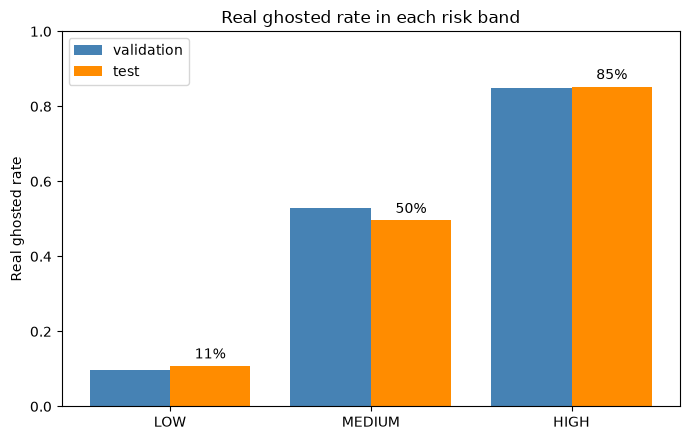

,users,real_ghosted_rate,mean_predicted_risk,share_of_users
band,,,,
LOW,945,0.108,0.100,0.345
MEDIUM,581,0.496,0.495,0.212
HIGH,1215,0.853,0.866,0.443


In [21]:
test_bands = band_table(y_test, test_proba)
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(3)
ax.bar(x - 0.2, val_bands['real_ghosted_rate'], 0.4, label='validation', color='steelblue')
ax.bar(x + 0.2, test_bands['real_ghosted_rate'], 0.4, label='test', color='darkorange')
for i, v in enumerate(test_bands['real_ghosted_rate']):
    ax.text(i + 0.2, v + 0.02, f'{v:.0%}', ha='center')
ax.set_xticks(x, ['LOW', 'MEDIUM', 'HIGH'])
ax.set_ylim(0, 1)
ax.set_ylabel('Real ghosted rate')
ax.set_title('Real ghosted rate in each risk band')
ax.legend()
plt.tight_layout()
plt.show()
test_bands.round(3)

# 13 Save the Model Package

## CELL 22: Write Model, Config and Model Card

In [22]:
OUT_DIR.mkdir(exist_ok=True)
versions = {'python': platform.python_version(), 'scikit-learn': sklearn.__version__, 'numpy': np.__version__,
            'pandas': pd.__version__, 'joblib': joblib.__version__}

joblib.dump({'model': app_model, 'model_name': APP_MODEL_NAME, 'model_version': MODEL_VERSION,
             'feature_columns': list(X_eng.columns), 'ordinal_features': ORDINAL_FEATURES,
             'nominal_columns': NOMINAL_COLS, 'night_label': NIGHT, 'versions': versions},
            OUT_DIR / 'ghost_guard_model.pkl')

config = {
    'model_version': MODEL_VERSION,
    'model_name': APP_MODEL_NAME,
    'created': date.today().isoformat(),
    'predicts': 'probability that the app user gets ghosted (survey target Ghosted_Experience)',
    'app_message': "Based on your dating profile and how you're messaging in this chat, your ghosting risk is <BAND>.",
    'not_for': 'saying whether a specific partner will ghost the user',
    'requires': versions,
    'questions': {'onboarding': ONBOARDING_QUESTIONS, 'measured_from_each_chat': CHAT_QUESTIONS,
                  'not_needed': NOT_USED, 'age_range': list(AGE_RANGE), 'profile_pics_range': [1, 8]},
    'allowed_answers': {q: LEVELS[q] for q in ONBOARDING_QUESTIONS if q != 'Age'},
    'chat_rules': CHAT_RULES,
    'bands': {'edges': list(BAND_EDGES), 'labels': ['LOW', 'MEDIUM', 'HIGH'],
              'real_ghosted_rate_validation': val_bands['real_ghosted_rate'].round(4).tolist(),
              'real_ghosted_rate_test': test_bands['real_ghosted_rate'].round(4).tolist()},
    'tips': {'eligible_questions': {q: ('higher level lowers risk' if d == 1 else 'lower level lowers risk')
                                    for q, d in TIP_RULES.items()},
             'min_risk_drop': 0.02, 'max_tips': 2,
             'never_used_for_tips': ['Age', 'Gender', 'Sexual_Orientation', 'Location_Type', 'Education_Level',
                                     'Income_Bracket_Self_Report']},
    'release_gates': gate_table.set_index('Model').loc[APP_MODEL_NAME].drop('Passes all gates').to_dict(),
    'test_metrics': {k: float(v) for k, v in test_summary.items()},
    'data': {'file': 'ghosting.csv', 'respondents': len(df), 'train': len(idx_train),
             'validation': len(idx_val), 'test': len(idx_test)},
}
config['release_gates'] = {k: (bool(v) if isinstance(v, (bool, np.bool_)) else float(v))
                           for k, v in config['release_gates'].items()}
with open(OUT_DIR / 'ghost_guard_config.json', 'w', encoding='utf-8') as fh:
    json.dump(config, fh, indent=2, ensure_ascii=False)

band_rows = '\n'.join(
    f"| {band} | {lo:.2f}-{hi:.2f} | {int(r.users):,} | {r.real_ghosted_rate:.1%} |"
    for (band, r), lo, hi in zip(test_bands.iterrows(), [0, *BAND_EDGES], [*BAND_EDGES, 1]))
card = f"""# Model Card: {MODEL_VERSION}

**Model:** {APP_MODEL_NAME}, trained on {len(idx_train):,} respondents from `ghosting.csv` (same cleaning, features and split as `Ghosting_Survey_ML_Pipeline_v2.ipynb`).

**Predicts:** the probability that the app user gets ghosted.

**App message:** "Based on your dating profile and how you're messaging in this chat, your ghosting risk is LOW / MEDIUM / HIGH."

**Not for:** saying whether a specific partner will ghost the user.

## Inputs
- **Onboarding ({len(ONBOARDING_QUESTIONS)} questions):** {', '.join(ONBOARDING_QUESTIONS)}
- **Re-measured from each chat:** {', '.join(CHAT_QUESTIONS)} (onboarding answer used when the chat is too short)
- **Not needed:** country, interests

## Performance (test set, {len(idx_test):,} respondents, used once)
| Scenario | ROC-AUC |
|---|---|
| Survey answers | {test_summary['ROC-AUC']:.3f} (95% CI {test_summary['ROC-AUC 95% CI low']:.3f}-{test_summary['ROC-AUC 95% CI high']:.3f}) |
| 50% of users' chat answers off by up to one level | {test_summary['ROC-AUC, 50% of chat answers off']:.3f} |
| Chat answers completely random | {test_summary['ROC-AUC, chat answers completely random']:.3f} |

Accuracy at 0.5: {test_summary['Accuracy at 0.5']:.1%} | Balanced accuracy: {test_summary['Balanced accuracy at 0.5']:.1%} | Brier score: {test_summary['Brier score']:.3f}

## Risk bands (test)
| Band | Risk score | Users | Real ghosted rate |
|---|---|---|---|
{band_rows}

## Tips
Only for questions whose effect points the same way for every validation user: {', '.join(TIP_RULES) or 'none'}. Never based on age, gender, orientation, location, education or income.

## Limits
- Accuracy with **real** chat measurements is not yet known; the chat-to-answer rules are provisional.
- Survey answers are self-reported, and "ghosted" means ever ghosted, not ghosted in this chat.
- Users who report no matches always score LOW.
- Real-world accuracy must be measured with the 14-day outcome follow-up before it is claimed in the app.

## Requirements
{', '.join(f'{k} {v}' for k, v in versions.items())}
"""
(OUT_DIR / 'MODEL_CARD.md').write_text(card, encoding='utf-8')
for f in sorted(OUT_DIR.iterdir()):
    print(f"{f.name:<28}{f.stat().st_size / 1024:>8.1f} KB")

ghost_guard_config.json          7.4 KB
ghost_guard_model.pkl           23.9 KB
MODEL_CARD.md                    2.1 KB


## CELL 23: Reload and Verify the Package

In [23]:
package = joblib.load(OUT_DIR / 'ghost_guard_model.pkl')
saved_config = json.load(open(OUT_DIR / 'ghost_guard_config.json', encoding='utf-8'))
assert np.allclose(package['model'].predict_proba(X_eng.loc[idx_test])[:, 1], test_proba)
assert saved_config['model_version'] == MODEL_VERSION
assert score_chat(HIGH_RISK_PROFILE, COLD, model=package['model']) == score_chat(HIGH_RISK_PROFILE, COLD)
print("Package reloads and reproduces the notebook's predictions and chat scores.")
print(f"The model file needs scikit-learn {sklearn.__version__}. The app backend currently pins 1.2.2 for the old "
      "chat model, so the backend version must be aligned when this model is installed.")

Package reloads and reproduces the notebook's predictions and chat scores.


The model file needs scikit-learn 1.9.0. The app backend currently pins 1.2.2 for the old chat model, so the backend version must be aligned when this model is installed.


# 14 Summary

The package in `app_model/`:

| File | Contents |
|---|---|
| `ghost_guard_model.pkl` | Trained app model plus the answer mappings needed to build its features |
| `ghost_guard_config.json` | Questions, allowed answers, chat rules, band cut-offs with real ghosted rates, tip rules, release gates, test metrics, library versions |
| `MODEL_CARD.md` | One-page summary for the thesis and the app work |

